# Xem du lieu

|File	|Nội dung|	Số lượng|
| --- | --- | --- |
|test-images-idx3-ubyte.gz	|Ảnh tập train|	60.000|
|train-labels-idx1-ubyte.gz |Nhãn tương ứng của ảnh train|  60.000|
|t10k-images-idx3-ubyte.gz	|Ảnh tập test|	10.000|
|t10k-labels-idx1-ubyte.gz	|Nhãn tương ứng của ảnh test|	10.000|



In [1]:
from pathlib import Path
from torchvision.datasets import MNIST

current_dir = Path.cwd()
PROJECT_ROOT = current_dir.parent 
RAW_DIR = PROJECT_ROOT / "data"
RAW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", RAW_DIR)

train_dataset = MNIST(
    root=str(RAW_DIR),
    train=True,
    download=True
)

test_dataset = MNIST(
    root=str(RAW_DIR),
    train=False,
    download=True 
)

Project root: /home/tim/General Code/Pattern_Recognition/WriteRHand
Dataset path: /home/tim/General Code/Pattern_Recognition/WriteRHand/data


## Kiểu dữ liệu & kích thước

In [2]:
print("Kiểu của đối tượng train_dataset:", type(train_dataset))
print("Kiểu của đối tượng test_dataset:", type(test_dataset))
print("Kích thước của đối tượng train_dataset:", type(train_dataset))
print("Kích thước của đối tượng test_dataset:", type(test_dataset))

Kiểu của đối tượng train_dataset: <class 'torchvision.datasets.mnist.MNIST'>
Kiểu của đối tượng test_dataset: <class 'torchvision.datasets.mnist.MNIST'>
Kích thước của đối tượng train_dataset: <class 'torchvision.datasets.mnist.MNIST'>
Kích thước của đối tượng test_dataset: <class 'torchvision.datasets.mnist.MNIST'>


Kiểu dữ liệu khi tải về mà không dùng `MNIST(... , transform=transform)` là một object dataset, cần biến đổi về dạng có thể xử lý.

In [3]:
train_images = train_dataset.data
train_labels = train_dataset.targets
print("Kieu du lieu cua train_dataset.data:", type(train_images))
print("Kieu du lieu cua train_dataset.targets:", type(train_labels))
print("Shape cua train_images:", train_images.shape)
print("Dtype cua train_images:", train_images.dtype)
print("Shape cua train_labels:", train_labels.shape)
print("Dtype cua train_labels:", train_labels.dtype)

Kieu du lieu cua train_dataset.data: <class 'torch.Tensor'>
Kieu du lieu cua train_dataset.targets: <class 'torch.Tensor'>
Shape cua train_images: torch.Size([60000, 28, 28])
Dtype cua train_images: torch.uint8
Shape cua train_labels: torch.Size([60000])
Dtype cua train_labels: torch.int64


`uint8` (Unsigned Integer 8-bit) là kiểu dữ liệu số nguyên không dấu 8-bit, lưu trữ các giá trị từ 0 đến 255 và là định dạng chuẩn để biểu diễn cường độ sáng của pixel ảnh (0 là đen, 255 là trắng)

In [4]:
test_images = test_dataset.data
test_labels = test_dataset.targets
print("Kieu du lieu cua test_dataset.data:", type(test_images))
print("Kieu du lieu cua test_dataset.targets:", type(test_labels))
print("Shape cua test_images:", test_images.shape)
print("Dtype cua test_images:", test_images.dtype)
print("Shape cua test_labels:", test_labels.shape)
print("Dtype cua test_labels:", test_labels.dtype)

Kieu du lieu cua test_dataset.data: <class 'torch.Tensor'>
Kieu du lieu cua test_dataset.targets: <class 'torch.Tensor'>
Shape cua test_images: torch.Size([10000, 28, 28])
Dtype cua test_images: torch.uint8
Shape cua test_labels: torch.Size([10000])
Dtype cua test_labels: torch.int64


In [5]:
print(train_images[0].shape)
print(train_images[0])

torch.Size([28, 28])
tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,  

Mỗi dòng sample image là 1 ma trận 28x28 chứa các giá trị uint8 thể hiện độ sáng pixel

In [6]:
print(train_labels[0])
print(train_labels[2])
print(train_labels[4])

tensor(5)
tensor(4)
tensor(9)


## Vẽ ảnh & phân phối nhãn

In [7]:
print("Min, max pixel trong tap train:", train_images.min().item(),
      train_images.max().item())
print("Min, max pixel trong tap test:", test_images.min().item(),
      test_images.max().item())

Min, max pixel trong tap train: 0 255
Min, max pixel trong tap test: 0 255


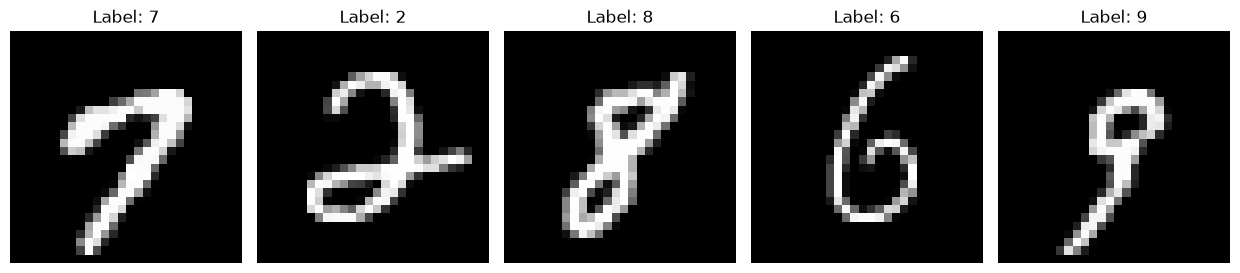

In [8]:
import matplotlib.pyplot as plt

def show_samples(images, labels, start=0, n=5):
    end = min(start + n, len(images))

    fig, axes = plt.subplots(
        1, end - start,
        figsize=(2.5 * (end - start), 3),
        squeeze=False # de ve mot hang n bieu do
    )

    for ax, i in zip(axes[0], range(start, end)):
        image = images[i]
        label = labels[i].item()


        ax.imshow(image, cmap="gray")
        ax.set_title(f"Label: {label}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(train_images, train_labels, start=15)

In [9]:
import torch

def label_count(labels):
    labs, counts = torch.unique(labels, return_counts=True)
    n = len(labels)
    for label, count in zip(labs, counts):
        print(f"Nhãn: {label}: {count},    tỷ lệ: {count*100/n:.1f}%")

label_count(train_labels)

Nhãn: 0: 5923,    tỷ lệ: 9.9%
Nhãn: 1: 6742,    tỷ lệ: 11.2%
Nhãn: 2: 5958,    tỷ lệ: 9.9%
Nhãn: 3: 6131,    tỷ lệ: 10.2%
Nhãn: 4: 5842,    tỷ lệ: 9.7%
Nhãn: 5: 5421,    tỷ lệ: 9.0%
Nhãn: 6: 5918,    tỷ lệ: 9.9%
Nhãn: 7: 6265,    tỷ lệ: 10.4%
Nhãn: 8: 5851,    tỷ lệ: 9.8%
Nhãn: 9: 5949,    tỷ lệ: 9.9%


Nhận xét: các nhãn có phân bố đồng đều, không quá xa 10%. Nhãn 1 nhiều nhất (11.2%), nhãn 5 ít nhất (9%)

# Xử lý dữ liệu

In [10]:
SEED = 42
torch.manual_seed(SEED)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(train_images), generator=g)
tr_idx, va_idx = perm[:50000], perm[50000:]

_X = train_images[tr_idx].reshape(-1, 784).float() / 255.0
MEAN, STD = _X.mean().item(), _X.std().item()


def preprocess(X_raw):
    return (X_raw.reshape(-1, 784).float() / 255.0 - MEAN) / STD


X_train, y_train = preprocess(train_images[tr_idx]), train_labels[tr_idx]
X_val, y_val = preprocess(train_images[va_idx]), train_labels[va_idx]
X_test, y_test = preprocess(test_images), test_labels

print(f"MEAN = {MEAN:.4f}, STD = {STD:.4f}")
print("X_train", tuple(X_train.shape), "| X_val", tuple(X_val.shape), "| X_test", tuple(X_test.shape))
print("So mau moi lop (train):", torch.bincount(y_train).tolist())

MEAN = 0.1307, STD = 0.3082
X_train (50000, 784) | X_val (10000, 784) | X_test (10000, 784)
So mau moi lop (train): [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985]


## Pixel có độ lệnh chuẩn 0

In [12]:
import numpy as np
# X_train có shape (N, 784)
std_moi_pixel = X_train.std(axis=0)        # độ lệch chuẩn của từng cột (pixel), shape (784,)
pixel_hang_so = (std_moi_pixel == 0)       # mảng True/False, True = pixel hằng số, shape (784,)

print("Số pixel có std = 0:", pixel_hang_so.sum().item())
print("Vị trí các pixel đó:", np.where(pixel_hang_so)[0])

Số pixel có std = 0: 71
Vị trí các pixel đó: [  0   1   2   3   4   5   6   7   8   9  10  11  16  17  18  19  20  21
  22  23  24  25  26  27  28  29  30  31  52  53  54  55  56  57  82  83
  84  85 110 111 112 140 141 168 196 364 476 532 560 644 645 671 672 673
 699 700 701 727 728 729 730 754 755 756 757 758 759 780 781 782 783]


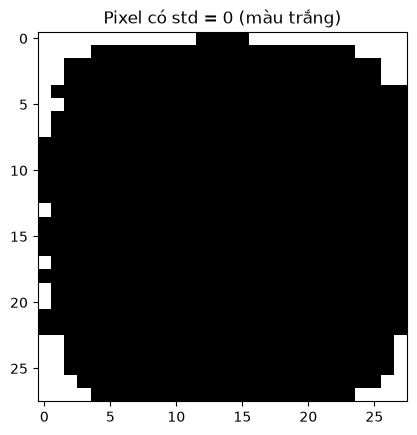

In [13]:
import matplotlib.pyplot as plt

mask_anh = pixel_hang_so.reshape(28, 28)      # đổi vector 784 thành ma trận 28x28

plt.imshow(mask_anh, cmap="gray")             # True hiện màu trắng, False hiện màu đen
plt.title("Pixel có std = 0 (màu trắng)")
plt.show()

## Ảnh trung bình

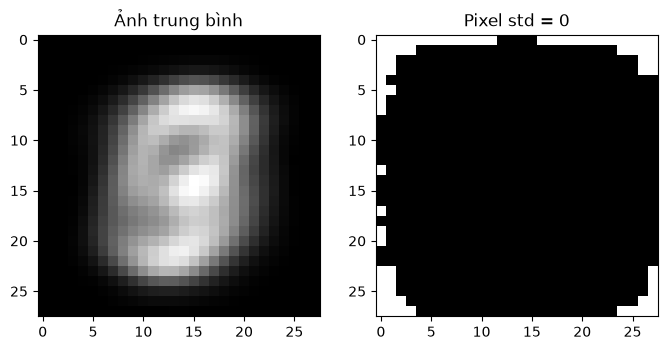

In [14]:
anh_trung_binh = X_train.mean(axis=0).reshape(28, 28)

plt.figure(figsize=(8, 4))                    # tạo khung hình rộng 8, cao 4

plt.subplot(1, 2, 1)                          # lưới 1 hàng 2 cột, vẽ ô thứ 1
plt.imshow(anh_trung_binh, cmap="gray")
plt.title("Ảnh trung bình")

plt.subplot(1, 2, 2)                          # vẽ ô thứ 2
plt.imshow(mask_anh, cmap="gray")
plt.title("Pixel std = 0")

plt.show()